# Titanic dimensionality reduction: Completed reference

**Question:** What profiles appear across passenger characteristics, and how do they relate to survival?

All application code is supplied. Saved runs make this notebook immediate to use; switch RECOMPUTE to True to fit nonlinear methods yourself.

The main live path is preparation, one fit_transform call per method, recoloring, and a return to original variables. The SVD and parameter sections are optional follow-up.

**Saved-run provenance:** PCA and t-SNE use scikit-learn, PHATE uses its Python implementation, and UMAP uses the official UMAP-js implementation. The Python UMAP recomputation branch uses umap-learn and was not executable in the authoring environment. The two implementations can produce different layouts. See [run details](../run_details.qmd).


## Setup

Run before class. The four saved runs are already computed for the bundled data. Install the recompute extra before using UMAP or PHATE fitting code.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

ROOT = Path.cwd()
if not (ROOT / "support/eda_helpers.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "support"))
from eda_helpers import prepare_titanic, prepare_tornadoes, load_saved, load_variant, plot_embedding

# False uses supplied runs and requires only the base environment.
# True recomputes nonlinear methods. First run: uv sync --extra recompute
RECOMPUTE = False


## Prepared features and plotting metadata

The supplied preparation function imputes numerical fields by the median, standardizes them, and imputes/one-hot encodes categorical fields. It retains all 891 passengers. Open `support/eda_helpers.py` to inspect the full pipeline.

| Embedding inputs | Preparation |
|---|---|
| age, fare, sibsp, parch | Median imputation, then z-scores |
| pclass, sex, embarked | Most-frequent imputation, then one-hot encoding |
| survived | Excluded from inputs, retained for color |
| Missingness indicators | Excluded from inputs, retained for color |

The numerical block and each categorical block contribute differently to Euclidean distances. This is one explicit definition of passenger similarity, not an automatically optimal choice.


In [2]:
df, X, feature_names, preprocessor = prepare_titanic(ROOT)
embeddings = {} if RECOMPUTE else load_saved(ROOT, "titanic", X, df["row_id"])
print("Prepared matrix:", X.shape)
print("Feature columns:", feature_names)
assert "survived" not in feature_names
df[["row_id", "age", "fare", "pclass", "sex", "survived"]].head()


Prepared matrix: (891, 12)
Feature columns: ['age', 'fare', 'sibsp', 'parch', 'pclass_1', 'pclass_2', 'pclass_3', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']


,row_id,age,fare,pclass,sex,survived
0,0,22.0,7.2500,3,male,0
1,1,38.0,71.2833,1,female,1
2,2,26.0,7.9250,3,female,1
3,3,35.0,53.1000,1,female,1
4,4,35.0,8.0500,3,male,0


## PCA: a linear baseline

Before running: what kind of information does this method prioritize?


Variance retained: 0.5376632912409538


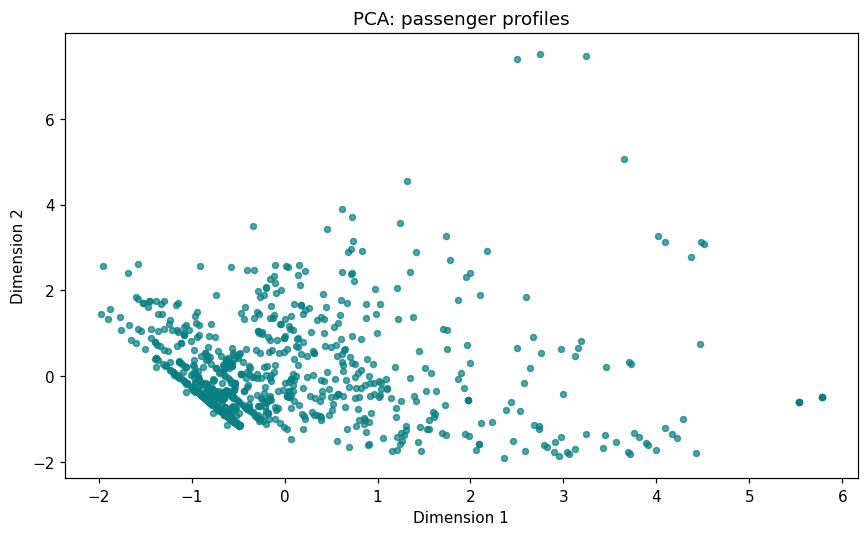

In [3]:
pca = PCA(n_components=2, svd_solver="full")
embeddings["PCA"] = pca.fit_transform(X)
print("Variance retained:", pca.explained_variance_ratio_.sum())
plot_embedding(embeddings["PCA"], df, title="PCA: passenger profiles")
plt.tight_layout()
plt.show()


**Interpretation:** PCA returns a coordinate for each passenger on each retained component. The first two retain about 53.8% of the variance of these prepared features. Variance is not a measure of relevance to survival.


## t-SNE: neighborhood similarities

Before running: what kind of information does this method prioritize?


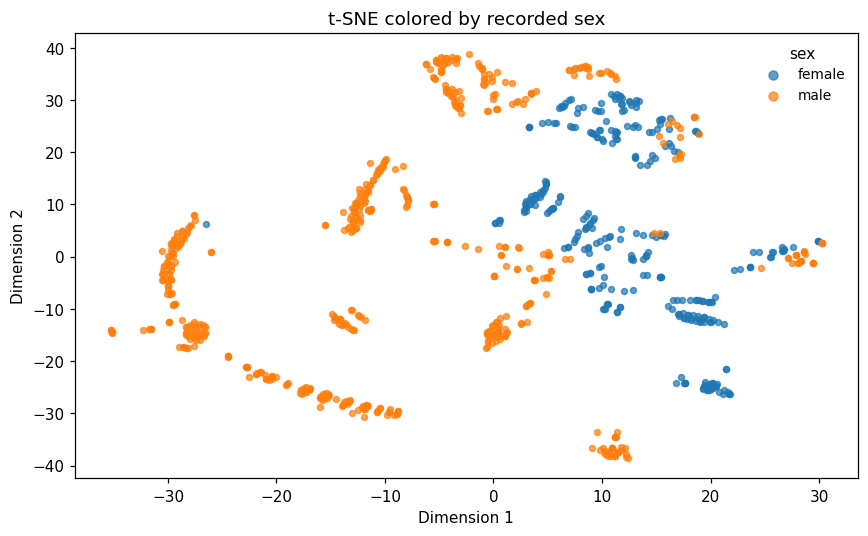

In [4]:
if RECOMPUTE:
    tsne = TSNE(n_components=2, perplexity=30, init="pca",
                learning_rate="auto", max_iter=1000, random_state=42)
    embeddings["t-SNE"] = tsne.fit_transform(X)

plot_embedding(embeddings["t-SNE"], df, "sex", "t-SNE colored by recorded sex")
plt.tight_layout()
plt.show()


**Interpretation:** Nearby points represent a neighborhood-based view of similarity. Inter-island spacing, island area, and point density do not provide faithful measurements of the original feature space.


## UMAP: a neighborhood graph

Before running: what kind of information does this method prioritize?


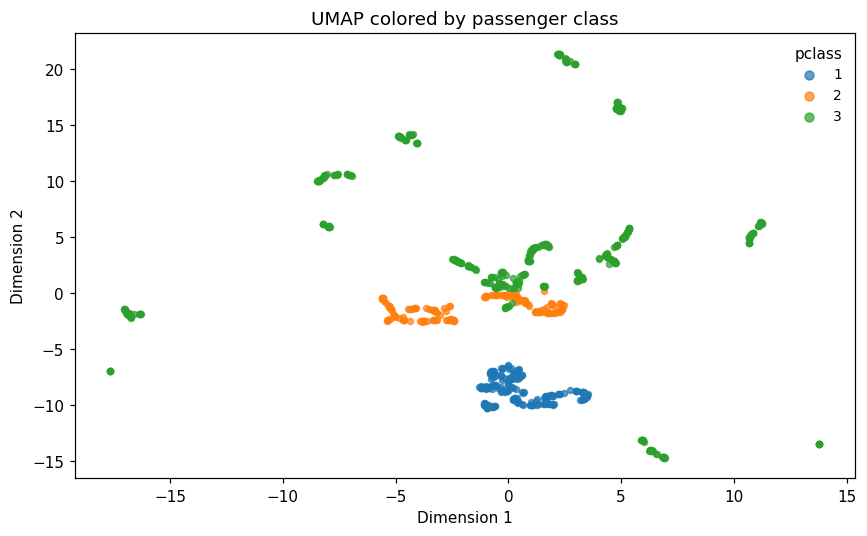

In [5]:
if RECOMPUTE:
    import umap
    reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                        metric="euclidean", random_state=42)
    embeddings["UMAP"] = reducer.fit_transform(X)

plot_embedding(embeddings["UMAP"], df, "pclass", "UMAP colored by passenger class")
plt.tight_layout()
plt.show()


**Interpretation:** n_neighbors controls the scale of neighborhoods used to build the graph. min_dist influences how tightly the layout packs points. Neither parameter certifies that visible islands are distinct populations.


## PHATE: diffusion and broader structure

Before running: what kind of information does this method prioritize?


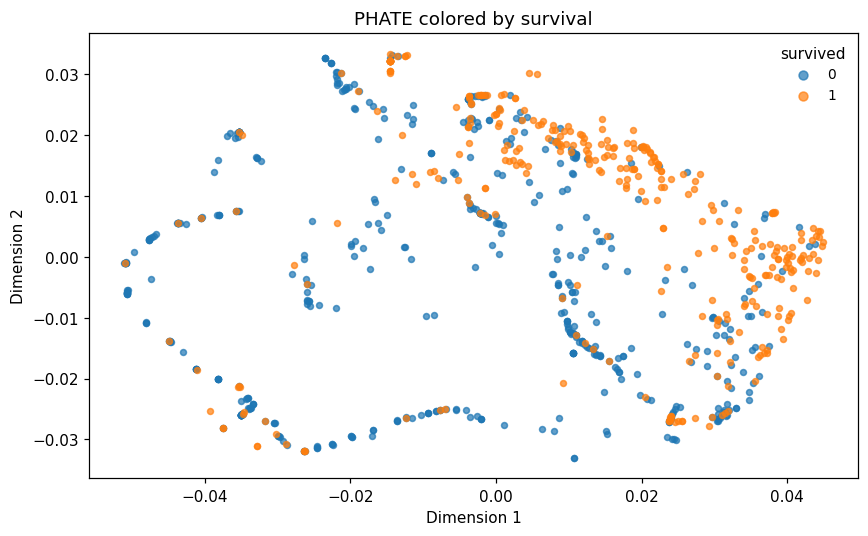

In [6]:
if RECOMPUTE:
    import phate
    reducer = phate.PHATE(n_components=2, knn=30, t="auto",
                          mds_solver="smacof", random_state=42,
                          n_jobs=1, verbose=0)
    embeddings["PHATE"] = reducer.fit_transform(X)

plot_embedding(embeddings["PHATE"], df, "survived", "PHATE colored by survival")
plt.tight_layout()
plt.show()


**Interpretation:** PHATE compares diffusion profiles on a graph before producing a low-dimensional layout. This can help inspect continuous structure. Diffusion steps are not elapsed time, and a branch does not establish a passenger trajectory. We use knn=30 because repeated feature profiles occur in this dataset, retain all passengers, and add no jitter.


## Recolor the same coordinates

Choose a method and a variable, then rerun this cell. Recoloring does not refit the embedding. Compare an input feature, a missingness indicator, and survival, which was withheld.

Options: sex, pclass, age, fare, age_is_missing, embarked_is_missing, survived.


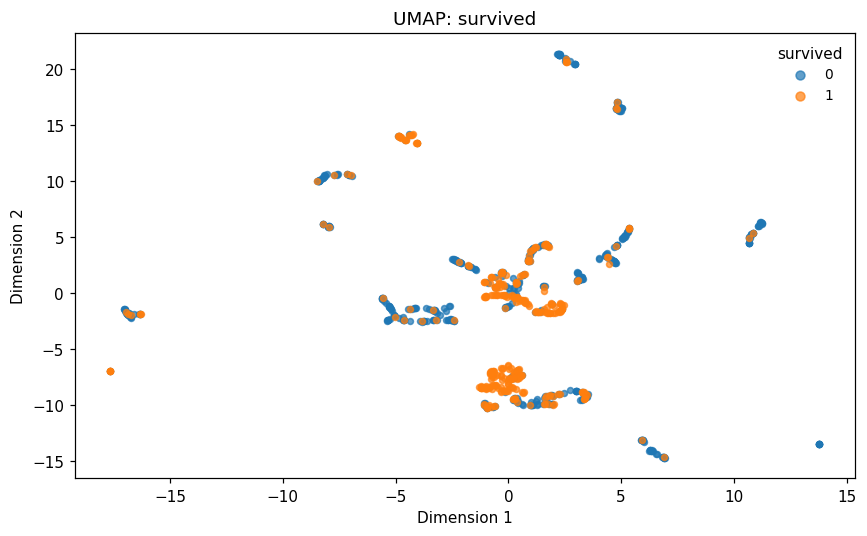

In [7]:
METHOD = "UMAP"
COLOR_BY = "survived"
plot_embedding(embeddings[METHOD], df, COLOR_BY, f"{METHOD}: {COLOR_BY}")
plt.tight_layout()
plt.show()


## A pattern becomes another question

Does apparent survival separation simply reflect passenger class and sex? Return to the original variables and compare proportions with explicit denominators.


passengers  survivors  survival_proportion
pclass sex                                               
1      female          94         91                0.968
       male           122         45                0.369
2      female          76         70                0.921
       male           108         17                0.157
3      female         144         72                0.500
       male           347         47                0.135

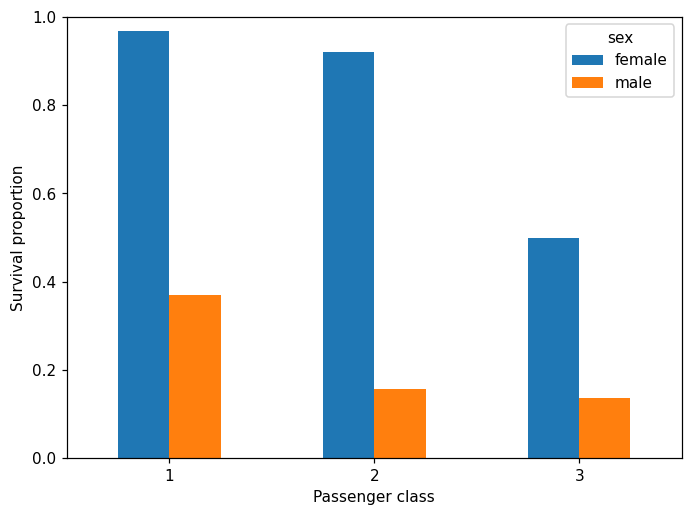

In [8]:
comparison = df.groupby(["pclass", "sex"])["survived"].agg(
    passengers="size", survivors="sum", survival_proportion="mean"
)
display(comparison.round(3))
ax = comparison["survival_proportion"].unstack("sex").plot.bar(rot=0)
ax.set(xlabel="Passenger class", ylabel="Survival proportion", ylim=(0, 1))
plt.tight_layout()
plt.show()


## Optional: inspect a region and compare it with the remaining passengers

This example takes the rightmost 20% of one layout as a convenient inspection region. It does not define a validated cluster. Axis direction is arbitrary and the region changes if the embedding rotates or changes settings.


In [9]:
coords = embeddings["UMAP"]
in_region = coords[:, 0] > np.quantile(coords[:, 0], 0.8)
regions = df.assign(region=np.where(in_region, "Selected region", "Remaining passengers"))
display(regions.groupby("region").agg(
    n=("row_id", "size"), survival=("survived", "mean"),
    average_fare=("fare", "mean"), missing_age=("age_is_missing", "mean")
).round(3))
display(pd.crosstab(regions["region"], regions["pclass"], normalize="index").round(3))


,n,survival,average_fare,missing_age
region,,,,
Remaining passengers,713,0.447,37.218,0.192
Selected region,178,0.129,12.122,0.225


pclass,1,2,3
region,,,
Remaining passengers,0.281,0.258,0.461
Selected region,0.090,0.000,0.910


## Optional: connect SVD to PCA

For centered X, X = U diag(s) Vt. The first two right singular vectors define directions. U[:, :2] * s[:2] gives point coordinates. A component's sign can flip without changing the represented geometry.


In [10]:
X_centered = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(X_centered, full_matrices=False)
svd_scores = U[:, :2] * s[:2]
variance = s**2 / (len(X) - 1)
print("Variance fraction from SVD:", variance[:2].sum() / variance.sum())
display(pd.DataFrame(Vt[:2].T, index=feature_names, columns=["PC1 weight", "PC2 weight"]).round(3))
print("Scores shape:", svd_scores.shape)


Variance fraction from SVD: 0.5376632912409538
Scores shape: (891, 2)


,PC1 weight,PC2 weight
age,0.332,-0.584
fare,-0.340,-0.687
sibsp,-0.603,0.122
parch,-0.616,-0.020
pclass_1,-0.019,-0.277
pclass_2,0.020,0.011
pclass_3,-0.001,0.266
sex_female,-0.122,-0.061
sex_male,0.122,0.061
embarked_C,-0.013,-0.103


## Optional: a controlled parameter comparison

These supplied runs hold the dataset and preprocessing fixed. The example below compares t-SNE perplexity 5 with 30. Use the same color variable and avoid reading between-island distances as original distances.


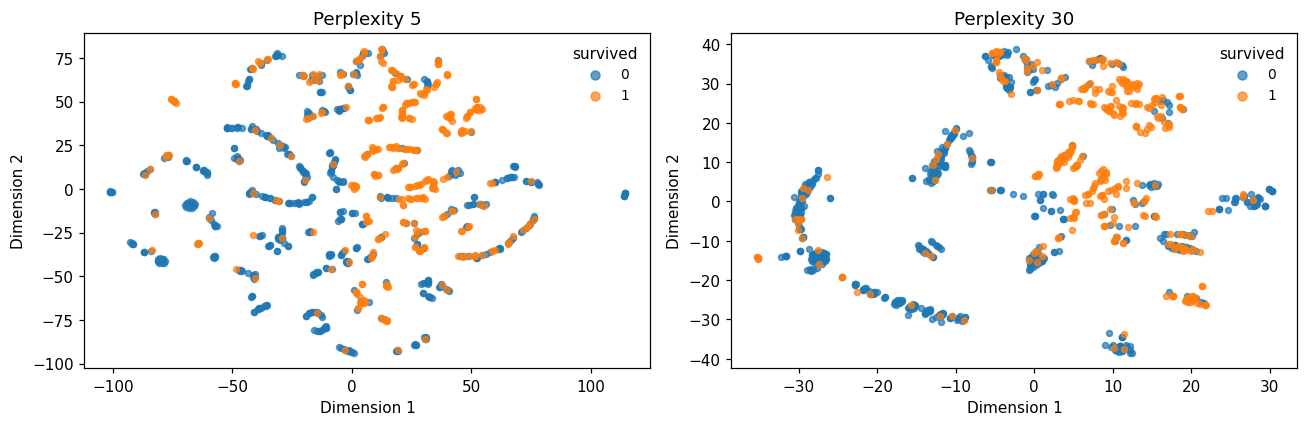

In [11]:
alternative = load_variant(ROOT, "tsne_perplexity_5", df["row_id"], X)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_embedding(alternative, df, "survived", "Perplexity 5", axes[0])
plot_embedding(load_variant(ROOT, "tsne", df["row_id"], X), df, "survived", "Perplexity 30", axes[1])
plt.tight_layout()
plt.show()


## Optional: UMAP and PHATE sensitivity

Other supplied variants: umap_neighbors_5, umap_neighbors_50, umap_min_dist_08, umap_seed_7, phate_t_2, phate_t_30. The source settings and implementation details appear in the run manifest.

PHATE's t changes diffusion smoothing. It is not a time variable measured on the passengers. Changing settings is a sensitivity check rather than a search for the prettiest plot.

**Next question:** Which interpretation survives a reasonable alternative view and an original-variable check?
